In [83]:
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_california_housing
from sklearn.linear_model import LinearRegression,Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
from  sklearn.ensemble import GradientBoostingRegressor

In [7]:
data=fetch_california_housing()

In [8]:
x=pd.DataFrame(data.data,columns=data.feature_names)
y=pd.DataFrame(data.target)

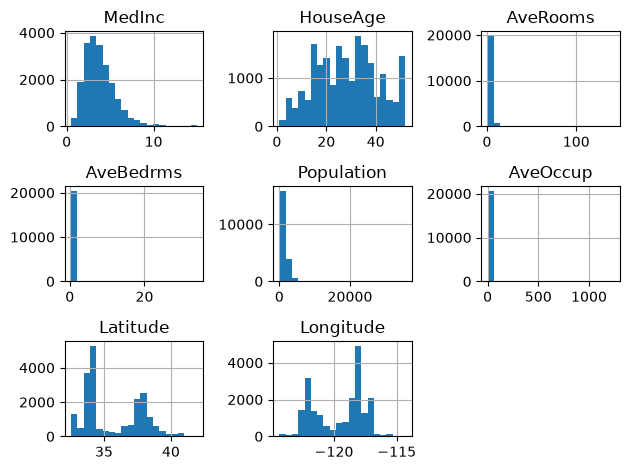

In [9]:
import matplotlib.pyplot as plt
x.hist(bins=20)
plt.tight_layout()

In [61]:
data.target_names

['MedHouseVal']

In [10]:
pip install seaborn

Note: you may need to restart the kernel to use updated packages.


In [11]:
x.corrwith(y.squeeze())

MedInc        0.688075
HouseAge      0.105623
AveRooms      0.151948
AveBedrms    -0.046701
Population   -0.024650
AveOccup     -0.023737
Latitude     -0.144160
Longitude    -0.045967
dtype: float64

In [12]:
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [13]:
from sklearn import set_config
set_config(transform_output='pandas')
from sklearn.preprocessing import StandardScaler
sc=StandardScaler()
X_train_final=sc.fit_transform(X_train)
X_test_final=sc.transform(X_test)

In [87]:
lr_model=LinearRegression()
lr_model.fit(X_train_final,y_train)

lr_train_pred=lr_model.predict(X_train_final)
lr_test_pred=lr_model.predict(X_test_final)

lr_train_r2_score=r2_score(y_train,lr_train_pred)
lr_test_r2_score=r2_score(y_test,lr_test_pred)

print('lr_train_r2_score',(lr_train_r2_score*100).__round__(2))
print('lr_test_r2_score',(lr_test_r2_score*100).__round__(2))


rdg_model=Ridge()
rdg_model.fit(X_train_final,y_train)

rdg_train_pred=rdg_model.predict(X_train_final)
rdg_test_pred=rdg_model.predict(X_test_final)

rdg_train_r2_score=r2_score(y_train,rdg_train_pred)
rdg_test_r2_score=r2_score(y_test,rdg_test_pred)
print('='*50)
print('rdg_train_r2_score',(rdg_train_r2_score*100).__round__(2))
print('rdg_test_r2_score',(rdg_test_r2_score*100).__round__(2))


rf_model=RandomForestRegressor(n_estimators=100,oob_score=True,bootstrap=True,n_jobs=-1,random_state=42)
rf_model.fit(X_train_final,y_train)

rf_train_pred=rf_model.predict(X_train_final)
rf_test_pred=rf_model.predict(X_test_final)

rf_train_r2_score=r2_score(y_train,rf_train_pred)
rf_test_r2_score=r2_score(y_test,rf_test_pred)
print('='*50)
print('rf_train_r2_score',(rf_train_r2_score*100).__round__(2))
print('rf_test_r2_score',(rf_test_r2_score*100).__round__(2))


gb_model=GradientBoostingRegressor(loss='squared_error', learning_rate=0.1,max_depth=5,)
gb_model.fit(X_train_final,y_train)

gb_train_pred=gb_model.predict(X_train_final)
gb_test_pred=gb_model.predict(X_test_final)

gb_train_r2_score=r2_score(y_train,gb_train_pred)
gb_test_r2_score=r2_score(y_test,gb_test_pred)
print('='*50)
print('gb_train_r2_score',(gb_train_r2_score*100).__round__(2))
print('gb_test_r2_score',(gb_test_r2_score*100).__round__(2))

lr_train_r2_score 61.26
lr_test_r2_score 57.58
rdg_train_r2_score 61.26
rdg_test_r2_score 57.58
rf_train_r2_score 97.35
rf_test_r2_score 80.47
gb_train_r2_score 86.95
gb_test_r2_score 81.18


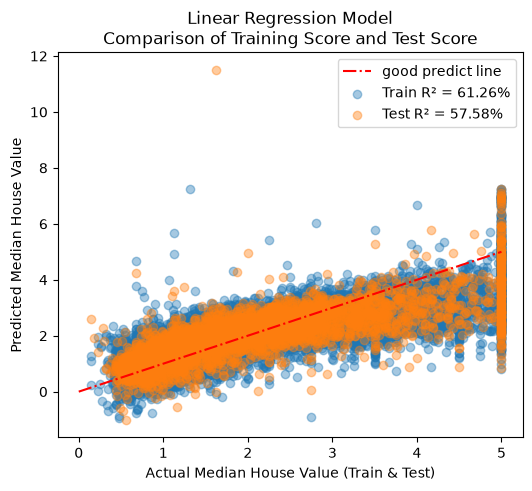

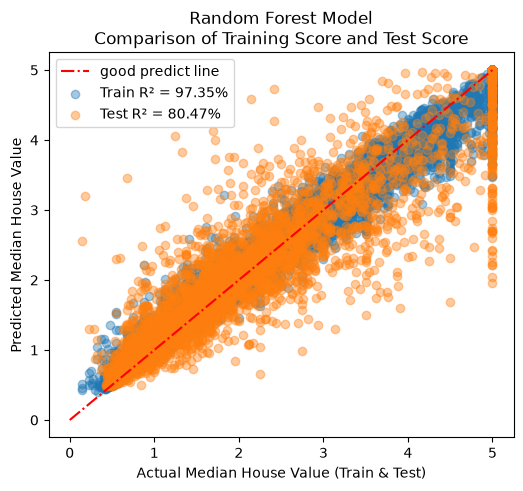

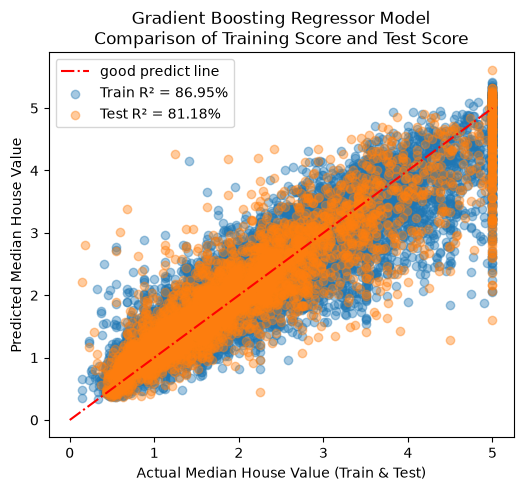

In [99]:
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score

def plot_model_results(y_train, train_pred, y_test, test_pred, title):
    plt.figure(figsize=(6, 5))
    
    train_score = r2_score(y_train, train_pred) * 100
    test_score = r2_score(y_test, test_pred) * 100
    plt.plot([0, 5], [0, 5],color='red',linestyle='-.',label='good predict line')

    plt.scatter(y_train, train_pred, alpha=0.4, label=f'Train R² = {train_score:.2f}%')
    plt.scatter(y_test, test_pred, alpha=0.4, label=f'Test R² = {test_score:.2f}%')
    
    plt.title(f"{title}\nComparison of Training Score and Test Score")
    plt.xlabel("Actual Median House Value (Train & Test)")
    plt.ylabel("Predicted Median House Value")
    plt.legend()
  
    plt.show()


plot_model_results(y_train, lr_train_pred, y_test, lr_test_pred, "Linear Regression Model")
plot_model_results(y_train, rf_train_pred, y_test, rf_test_pred, "Random Forest Model")
plot_model_results(y_train, gb_train_pred, y_test, gb_test_pred, "Gradient Boosting Regressor Model")